# Zelle 1: Imports & Style Setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Styling-Settings für übersichtliche Plots
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Zelle 2: Datensatz laden & Grundstruktur prüfen

In [3]:
# Daten aus dem SQL-Export laden
df = pd.read_csv('data/traveltide_user_aggregates_with_demographics.csv')

print(f"Anzahl Nutzer (Zeilen): {df.shape[0]:,}")
print(f"Anzahl Merkmale (Spalten): {df.shape[1]}")
print("-" * 50)
df.info()

Anzahl Nutzer (Zeilen): 50,000
Anzahl Merkmale (Spalten): 31
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 31 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   user_id                          50000 non-null  int64  
 1   birthdate                        50000 non-null  str    
 2   age                              50000 non-null  int64  
 3   gender                           50000 non-null  str    
 4   married                          50000 non-null  bool   
 5   has_children                     50000 non-null  bool   
 6   home_airport                     50000 non-null  str    
 7   home_country                     50000 non-null  str    
 8   home_airport_lat                 50000 non-null  float64
 9   home_airport_lon                 50000 non-null  float64
 10  total_sessions                   50000 no

## 2.b. Kohorten-Größe & Eindeutigkeit prüfen (Zeilenzahl-Check)
Stimmt die Anzahl der gefilterten Nutze und din alls user_ids wirklich eindeutig?

In [4]:
# Prüfen auf Eindeutigkeit
print(f"Zeilen gesamt: {len(df):,}")
print(f"Eindeutige User: {df['user_id'].nunique():,}")
assert len(df) == df['user_id'].nunique(), "Fehler: Duplikate in user_id!"

Zeilen gesamt: 50,000
Eindeutige User: 50,000


## 2.c. Aggregations-Vergleich (Random-Sample Spot Check)
Hierfür wird zur Verifikation ein zur Kohorte passender Datensatz aus session, flights und hotels gezogen
> /*
Als Grundlage für die Verifikation des SQL-Pushdown vs. Python-Heavy-Way
Ziehe ich die Kohorte einmalig direkt aus der Sessions Tabelle
*/
WITH cohort_users AS (
    -- 1. Deterministische Ermittlung der 50.000 Kohorten-User (ORDER BY user_id ASC)
    SELECT 
        user_id
    FROM sessions
    WHERE session_start >= '2023-01-05'
    GROUP BY user_id
    HAVING COUNT(DISTINCT session_id) >= 4 
       AND COUNT(DISTINCT trip_id) >= 1
    ORDER BY user_id ASC
    LIMIT 50000
),
valid_flights AS (
    -- 2. Nur gültige Flugdaten filtern
    SELECT trip_id
    FROM flights
    WHERE base_fare_usd > 0 
      AND seats > 0 
      AND (return_time IS NULL OR return_time > departure_time)
),
valid_hotels AS (
    -- 3. Nur gültige Hoteldaten filtern
    SELECT trip_id
    FROM hotels
    WHERE nights > 0
      AND hotel_per_room_usd > 0
      AND check_in_time IS NOT NULL 
      AND check_out_time IS NOT NULL
      AND check_out_time > check_in_time
)
-- 4. Unaggregierte Roh-Sessions genau dieser 50.000 Kohorten-User abrufen
SELECT 
    s.*
FROM sessions s
JOIN cohort_users cu 
    ON s.user_id = cu.user_id
LEFT JOIN valid_flights vf ON s.trip_id = vf.trip_id
LEFT JOIN valid_hotels vh  ON s.trip_id = vh.trip_id
WHERE s.session_start >= '2023-01-05'
  -- Qualitätsfilter: Verwirft Sessions mit fehlerhaften Trips
  AND (s.trip_id IS NULL OR vf.trip_id IS NOT NULL OR vh.trip_id IS NOT NULL)
ORDER BY s.user_id ASC, s.session_start ASC;

In [14]:
# Roh-Sessions laden
df_sessions = pd.read_csv('data/final_ORDER_BY_LIMIT-50k_verificaction-2026-10-23_25240.csv')
df_sql = pd.read_csv('data/final_ORDER_BY_LIMIT-50k-users_aggregate_with_demographics-2026-10-23_24107.csv')
# Stichprobe von 3 Usern
sample_users = df_sql['user_id'].sample(3, random_state=42).tolist()

# 1. Aggregation in Python für die Stichprobe
py_check = df_sessions[df_sessions['user_id'].isin(sample_users)].groupby('user_id').agg(
    total_sessions=('session_id', 'nunique'),
    avg_clicks=('page_clicks', 'mean')
)

# 2. Gegenprobe mit deinen SQL-Aggregaten
sql_check = df_sql[df_sql['user_id'].isin(sample_users)][['user_id', 'total_sessions', 'avg_page_clicks']].set_index('user_id')

print("--- OHNE AGGREGATION ---")
print(py_check)
print("\n--- MIT SQL AGGREGATION ---")
print(sql_check)

--- OHNE AGGREGATION ---
         total_sessions  avg_clicks
user_id                            
7930                  4        14.0
161348                4        11.5

--- MIT SQL AGGREGATION ---
         total_sessions  avg_page_clicks
user_id                                 
7930                  4             14.0
161348                4             11.5
322149                4             15.5


In [16]:
# 1. Nur User-IDs wählen, die wirklich in BEIDEN Dateien vorkommen
common_users = set(df_sql['user_id']).intersection(set(df_sessions['user_id']))

# 2. Stichprobe aus der gemeinsamen Schnittmenge ziehen
sample_users = pd.Series(list(common_users)).sample(3, random_state=42).tolist()

# 3. Python Aggregation
py_check = df_sessions[df_sessions['user_id'].isin(sample_users)].groupby('user_id').agg(
    total_sessions=('session_id', 'nunique'),
    avg_clicks=('page_clicks', 'mean')
)

# 4. Gegenprobe SQL
sql_check = df_sql[df_sql['user_id'].isin(sample_users)][['user_id', 'total_sessions', 'avg_page_clicks']].set_index('user_id')

print("--- OHNE AGGREGATION ---")
print(py_check)
print("\n--- MIT SQL AGGREGATION ---")
print(sql_check)

--- OHNE AGGREGATION ---
         total_sessions  avg_clicks
user_id                            
75820                 4        9.25
84385                 4       32.50
112209                4       27.25

--- MIT SQL AGGREGATION ---
         total_sessions  avg_page_clicks
user_id                                 
75820                 4             9.25
84385                 4            32.50
112209                4            27.25


# Zelle 3: Umgang mit Null-Werten (Missing Values)
Hintergrund: Da manche User zwar Flüge, aber keine Hotels gebucht haben (oder umgekehrt), entstehen in Aggregatspalten wie avg_hotel_nights oder avg_checked_bags_per_flight natürlicherweise NaN-Werte. Diese füllen wir sachlogisch mit 0.

In [6]:
# 1. Übersicht über fehlende Werte
missing_summary = df.isnull().sum()[df.isnull().sum() > 0]
print("Fehlende Werte pro Spalte:\n", missing_summary)

# 2. Imputation: Wo keine Buchung vorlag, ist die Anzahl/Ausgabe = 0
fill_zero_cols = [
    'total_flights_booked', 'total_seats_booked', 'total_checked_bags', 
    'avg_checked_bags_per_flight', 'total_flight_spend_usd', 'avg_flight_price_usd',
    'total_hotels_booked', 'total_hotel_nights', 'avg_hotel_nights', 
    'total_hotel_spend_usd', 'avg_room_price_per_night_usd',
    'avg_flight_discount_pct', 'avg_hotel_discount_pct', 'cancellation_rate_pct',
    'combined_flight_and_hotel_trips'
]

# Vorhandene Spalten mit 0 auffüllen
for col in fill_zero_cols:
    if col in df.columns:
        df[col] = df[col].fillna(0)

print("\nNull-Werte erfolgreich behandelt!")

Fehlende Werte pro Spalte:
 avg_flight_discount_pct         22953
avg_hotel_discount_pct          27451
cancellation_rate_pct              75
total_seats_booked               4479
total_checked_bags               4479
avg_checked_bags_per_flight      4479
total_flight_spend_usd           4479
avg_flight_price_usd             4479
total_hotel_nights               4650
avg_hotel_nights                 4650
total_hotel_spend_usd            4650
avg_room_price_per_night_usd     4650
dtype: int64

Null-Werte erfolgreich behandelt!


# Zelle 4: Erster statistischer Überblick (df.describe())

In [7]:
# Numerische Spalten analysieren
df.describe().T[['mean', 'std', 'min', '50%', 'max']]

,mean,std,min,50%,max
user_id,257587.651980,96377.104030,55.000,277754.000,387176.000
age,44.059500,11.419578,19.000,44.000,93.000
home_airport_lat,38.498723,6.105863,21.316,39.175,61.251
home_airport_lon,-94.025041,18.108673,-157.927,-89.977,-63.499
total_sessions,4.431360,0.705704,2.000,4.000,9.000
avg_page_clicks,20.061403,12.433688,2.670,17.000,166.250
flight_discount_sessions,0.817720,0.823886,0.000,1.000,5.000
hotel_discount_sessions,0.660640,0.752972,0.000,1.000,5.000
avg_flight_discount_pct,0.075958,0.090913,0.000,0.050,0.850
avg_hotel_discount_pct,0.050038,0.067637,0.000,0.000,0.550


# Zelle 5 Ausreißer-Analyse & Verteilung

In [8]:
# Ausgewählte Kernmerkmale mit auffälligen Extremwerten untersuchen
outlier_cols = [
    'avg_page_clicks', 
    'cancellation_rate_pct', 
    'total_flight_spend_usd', 
    'avg_flight_price_usd', 
    'avg_room_price_per_night_usd', 
    'combined_flight_and_hotel_trips'
]

# Filter nur auf Spalten, die tatsächlich im Dataframe existieren
available_cols = [col for col in outlier_cols if col in df.columns]

# Perzentil-Übersicht (05%, 50%, 95%, 99% und Max)
print("Perzentil-Analyse der Kernmetriken:")
df[available_cols].quantile([0.05, 0.50, 0.95, 0.99, 1.00]).T

Perzentil-Analyse der Kernmetriken:


,0.05,0.50,0.95,0.99,1.00
avg_page_clicks,9.14,17.000,48.500,70.7500,166.25
cancellation_rate_pct,0.00,0.000,50.000,100.0000,100.00
total_flight_spend_usd,0.00,648.075,3718.802,9683.8762,47788.47
avg_flight_price_usd,0.00,374.670,1873.397,4922.6553,23168.72
avg_room_price_per_night_usd,0.00,148.000,347.000,508.0000,1572.00
combined_flight_and_hotel_trips,0.00,1.000,3.000,4.0000,6.00


# Zelle 6
## Verteilung Visualisieren per Boxplots

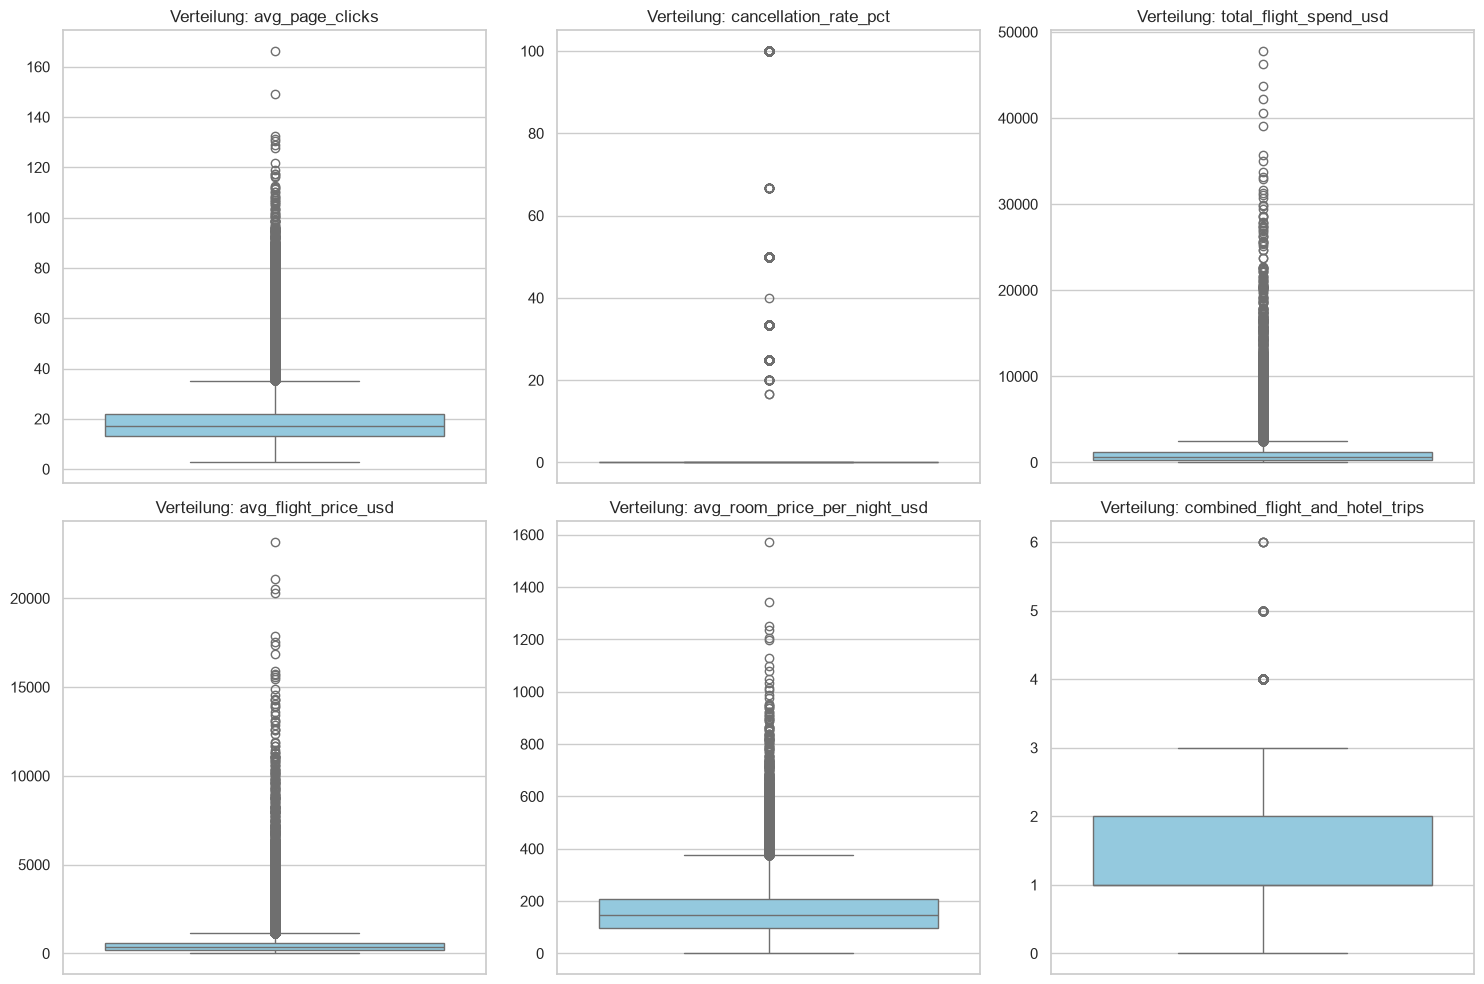

In [9]:
# Boxplots zur visuellen Identifikation von Ausreißern
plt.figure(figsize=(15, 10))

for i, col in enumerate(available_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(f'Verteilung: {col}')
    plt.ylabel('')

plt.tight_layout()
plt.show()

# Zelle 8
1. Perzentil Ranking für die normierte Skalierung

Damit wird die Auswirkung von AUssreißern und Extremwerten vermindert

2. Cappung am 99%-Quantil

Damit werden Extremwerte sozusagen gedeckelt

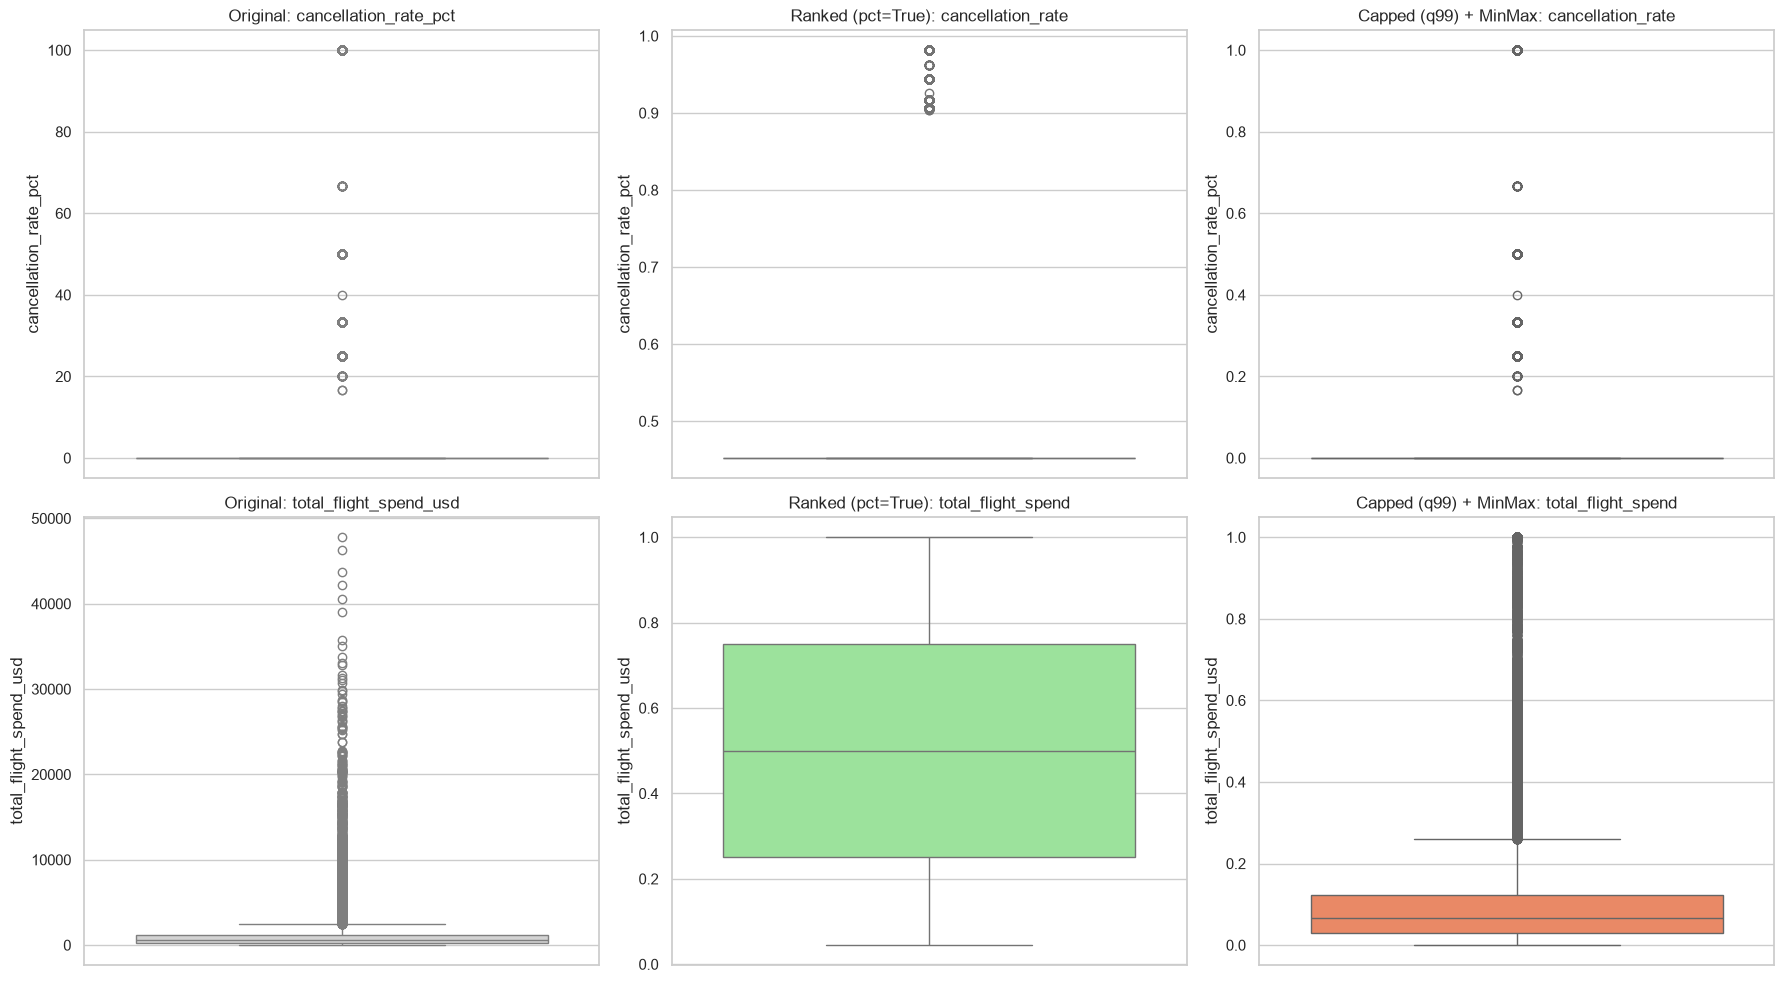

In [10]:
# 1. Perzentil-Ranking anwenden
df_ranked = df[available_cols].rank(pct=True)

# 2. Capping (am 99%-Quantil) + MinMax-Skalierung anwenden
df_capped = df[available_cols].copy()
for col in available_cols:
    q99 = df_capped[col].quantile(0.99)
    df_capped[col] = np.minimum(df_capped[col], q99)
    # MinMax-Skalierung auf [0, 1]
    col_min = df_capped[col].min()
    col_max = df_capped[col].max()
    if col_max > col_min:
        df_capped[col] = (df_capped[col] - col_min) / (col_max - col_min)

# Visualisierung des Vergleichs für cancellation_rate_pct und total_flight_spend_usd
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# cancellation_rate_pct: Original vs. Ranked vs. Capped
sns.boxplot(y=df['cancellation_rate_pct'], ax=axes[0, 0], color='lightgray').set_title('Original: cancellation_rate_pct')
sns.boxplot(y=df_ranked['cancellation_rate_pct'], ax=axes[0, 1], color='lightgreen').set_title('Ranked (pct=True): cancellation_rate')
sns.boxplot(y=df_capped['cancellation_rate_pct'], ax=axes[0, 2], color='coral').set_title('Capped (q99) + MinMax: cancellation_rate')

# total_flight_spend_usd: Original vs. Ranked vs. Capped
sns.boxplot(y=df['total_flight_spend_usd'], ax=axes[1, 0], color='lightgray').set_title('Original: total_flight_spend_usd')
sns.boxplot(y=df_ranked['total_flight_spend_usd'], ax=axes[1, 1], color='lightgreen').set_title('Ranked (pct=True): total_flight_spend')
sns.boxplot(y=df_capped['total_flight_spend_usd'], ax=axes[1, 2], color='coral').set_title('Capped (q99) + MinMax: total_flight_spend')

plt.tight_layout()
plt.show()

### total_flight_spend:   
* Vorher (grau): Der IQR (blaue/graue Box) klebt völlig platt am Boden, weil wenige Riesen-Ausgaben das Diagramm bis $50.000\,\$$ hochziehen.  
* Nach dem Perzentil-Ranking (grün): Die Box spannt sich wunderschön von $0.25$ bis $0.75$ auf! Das ist ein perfektes Lehrbuchbeispiel für eine gleichmäßige Gleichverteilung über den gesamten Raum $[0.0, 1.0]$

# Zelle 9
Bereinigten Datensatz zur Weitervearbeitung als CSV-Datei speichern

In [11]:
# Bereinigten Datensatz aus der EDA für das Feature Engineering speichern
df.to_csv('data/traveltide_user_aggregated_eda.csv', index=False)
print("Bereinigter EDA-Datensatz erfolgreich unter 'data/traveltide_user_aggregates_eda.csv' gespeichert!")

Bereinigter EDA-Datensatz erfolgreich unter 'data/traveltide_user_aggregates_eda.csv' gespeichert!


# Zelle 10 
Nun wollen wir mal schauen, wie international TravelTide tatsächlich ist

In [12]:
import pandas as pd

# 1. Quell-Datei laden
df_raw = pd.read_csv('data/traveltide_user_aggregates_with_demographics.csv')

print(f"Gesamtanzahl User im Datensatz: {len(df_raw):,}\n")

# A) Verteilung der Länder
country_counts = df_raw['home_country'].value_counts(dropna=False)
country_pct = (
    df_raw['home_country'].value_counts(dropna=False, normalize=True) * 100
)
df_countries = pd.DataFrame(
    {'Anzahl_User': country_counts, 'Prozent_Anteil': country_pct.round(2)}
)

print("=== LÄNDERVERTEILUNG ===")
print(df_countries)
print("\n" + "=" * 40 + "\n")

# B) Verteilung der Bundesstaaten / Provinzen (falls home_state vorhanden)
if 'home_state' in df_raw.columns:
  state_counts = df_raw['home_state'].value_counts(dropna=False)
  state_pct = (
      df_raw['home_state'].value_counts(dropna=False, normalize=True) * 100
  )
  df_states = pd.DataFrame(
      {'Anzahl_User': state_counts, 'Prozent_Anteil': state_pct.round(2)}
  )

  print("=== TOP 15 BUNDESSTAATEN / PROVINZEN (inkl. NaN) ===")
  print(df_states.head(15))
  print(f"\nFehlende/Unbekannte States (NaN): {df_raw['home_state'].isna().sum():,}")

Gesamtanzahl User im Datensatz: 50,000

=== LÄNDERVERTEILUNG ===
              Anzahl_User  Prozent_Anteil
home_country                             
usa                 41674           83.35
canada               8326           16.65




# Zelle 11
Mapping-Analyse zwischen IATA-Flughäfen & US/CA Filter 

In [13]:
# 1. Airports-Referenztabelle (OurAirports) laden & filtern
url_regions = 'https://raw.githubusercontent.com/davidmegginson/ourairports-data/main/airports.csv'
df_our_airports = pd.read_csv(url_regions)

# Strikter Filter auf US & CA und valide IATA-Codes
df_airports_filtered = df_our_airports[
    df_our_airports['iso_country'].isin(['US', 'CA'])
].copy()
df_airports_filtered['state_code'] = (
    df_airports_filtered['iso_region'].str.split('-').str[1]
)

lookup_df = (
    df_airports_filtered[['iata_code', 'state_code', 'municipality']]
    .dropna(subset=['iata_code'])
    .drop_duplicates(subset=['iata_code'])
)

# 2. Merge mit den 50.000 Kohorten-Usern durchführen
df_merged = df_raw.merge(
    lookup_df, left_on='home_airport', right_on='iata_code', how='left'
)

# 3. Matching-Analyse & Mismatch-Statistik
matched_users = df_merged['state_code'].notna().sum()
mismatched_users = df_merged['state_code'].isna().sum()

print("=== MAPPING-ERGEBNIS (home_airport -> US/CA State) ===")
print(f"Gesamtanzahl User:               {len(df_raw):,}")
print(
    f"Erfolgreich gematchte User:       {matched_users:,} "
    f"({matched_users/len(df_raw)*100:.2f}%)"
)
print(
    f"Nicht gematchte User (Mismatch): {mismatched_users:,} "
    f"({mismatched_users/len(df_raw)*100:.2f}%)\n"
)

# 4. Ursachen-Analyse der Mismatches
missing_airports = df_merged[df_merged['state_code'].isna()][
    'home_airport'
].value_counts()
print("Top 10 home_airports ohne Treffer in US/CA-Referenzliste:")
print(missing_airports.head(10))

=== MAPPING-ERGEBNIS (home_airport -> US/CA State) ===
Gesamtanzahl User:               50,000
Erfolgreich gematchte User:       48,070 (96.14%)
Nicht gematchte User (Mismatch): 1,930 (3.86%)

Top 10 home_airports ohne Treffer in US/CA-Referenzliste:
home_airport
YZD    502
YKZ    476
YXD    226
YED    217
YAW    154
NCA    125
AKR    118
NZC    112
Name: count, dtype: int64
